# How can we model segregation from longitudinal data?

We can measure segregation, using definitions similar to [*Mobility patterns are associated with experienced income segregation in large US cities*](https://www.nature.com/articles/s41467-021-24899-8#MOESM1) and [*Estimating experienced racial segregation in US cities using large-scale GPS data*](https://www.pnas.org/doi/10.1073/pnas.2026160118). How can we model segregation in relation to heat?

* MSA-level fixed effects models with fixed effect on $t$ and $MSA$, modeling aggregate effect of heat
* POI-level fixed effects model for understanding change in POIs over types
* DID comparing MSAs with normal weather (*control*) with MSAs with abnormal (*treatment*)

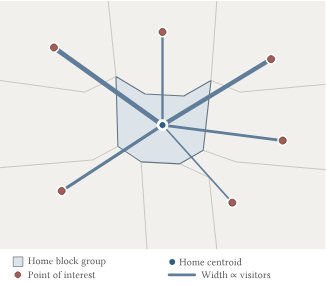

In [1]:
from datetime import datetime, timedelta, date
import math
from pathlib import Path

import duckdb
import contextily as cx
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import networkx as nx
import numpy as np
import orjson
import pandas as pd
import polars as pl
import seaborn as sns
import shapely
import statsmodels.formula.api as smf
from tqdm import tqdm

from wpp import db
from wpp.segregation import data
from wpp.utils import project_root

In [2]:
# config
sns.set_theme(style="ticks")

root = project_root()
db_path = root / "wpp.duckdb"
con = db.connect(db_path)

In [3]:
prism = con.sql("""
    SELECT DATE, CBSAFP, SUM(tmean * CBSA_WEIGHT) AS AVG_TMEAN
    FROM prism_t_daily t
    JOIN cbsa_prism_cells c ON t.CELL_ID = c.CELL_ID
    GROUP BY 1, 2
    ORDER BY 1, 2
""").pl()
prism.head()

DATE,CBSAFP,AVG_TMEAN
date,str,f64
2025-01-01,"""10100""",-5.431155
2025-01-01,"""10140""",3.682551
2025-01-01,"""10180""",6.180245
2025-01-01,"""10220""",4.763571
2025-01-01,"""10300""",2.204651


In [4]:
n_income_groups = 4
query = f"""
    WITH bg AS MATERIALIZED (
        SELECT
            GEOID, CBSAFP, CBSA_NAME, CBSA_POP_RANK,
            MEDIAN_HH_INCOME,
            NTILE({n_income_groups}) OVER (
                PARTITION BY CBSAFP ORDER BY MEDIAN_HH_INCOME ASC
            ) AS INCOME_GROUP
        FROM block_groups_cbsa
        WHERE LSAD = 'M1'
          AND MEDIAN_HH_INCOME IS NOT NULL
    )
    SELECT
        bgh.CBSAFP AS CBSAFP, String_split(bgh.CBSA_NAME, '-')[1] AS CBSA_NAME,
        bgv.DATE_RANGE_START, bgv.DATE_RANGE_END, bgv.HOME_GEOID,
        bgv.ID_STORE, bgv.VISITOR_COUNTS, bgv.DIST,
        p.POI_GEOID, bgp.INCOME_GROUP AS POI_INCOME_GROUP,
        bgh.MEDIAN_HH_INCOME AS HOME_MEDIAN_HH_INCOME,
        bgh.INCOME_GROUP AS HOME_INCOME_GROUP
    FROM block_group_visits_enhanced bgv
    JOIN pois p ON bgv.ID_STORE = p.ID_STORE
    JOIN bg bgp ON p.POI_GEOID = bgp.GEOID
    JOIN bg bgh ON bgv.HOME_GEOID = bgh.GEOID
    WHERE DATE_RANGE_START BETWEEN DATE'2025-01-01' AND DATE'2025-03-31'
"""
lf = con.sql(query).pl(lazy=True)
lf.head().collect()

CBSAFP,CBSA_NAME,DATE_RANGE_START,DATE_RANGE_END,HOME_GEOID,ID_STORE,VISITOR_COUNTS,DIST,POI_GEOID,POI_INCOME_GROUP,HOME_MEDIAN_HH_INCOME,HOME_INCOME_GROUP
str,str,datetime[μs],datetime[μs],str,str,i32,f64,str,i64,f64,i64
"""38060""","""Phoenix""",2025-01-06 00:00:00,2025-01-12 00:00:00,"""040130610511""","""12172231""",692,868.662857,"""040130610512""",3,114679.0,3
"""38060""","""Phoenix""",2025-01-06 00:00:00,2025-01-12 00:00:00,"""040130610511""","""12172240""",34,10705.226963,"""040130405314""",2,114679.0,3
"""38060""","""Phoenix""",2025-01-06 00:00:00,2025-01-12 00:00:00,"""040130610511""","""12176950""",69,7897.246348,"""040130612002""",1,114679.0,3
"""38060""","""Phoenix""",2025-01-06 00:00:00,2025-01-12 00:00:00,"""040130610511""","""12182231""",43,14875.611798,"""040130820242""",1,114679.0,3
"""38060""","""Phoenix""",2025-01-06 00:00:00,2025-01-12 00:00:00,"""040130610511""","""12190333""",21,54397.794624,"""040132168301""",2,114679.0,3


In [5]:
visits_per_day = lf.group_by("CBSA_NAME", "DATE_RANGE_START").agg(
    pl.col("VISITOR_COUNTS").sum(),
    ((pl.col("DIST") * pl.col("VISITOR_COUNTS")).sum() / pl.col("VISITOR_COUNTS").sum()).alias("DIST")
).sort("DATE_RANGE_START", "VISITOR_COUNTS", descending=[False, True]).collect()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

/Users/marfri/Desktop/weekly-patterns-plus-exploration/.venv/lib/python3.14/site-packages/seaborn/categorical.py:3399: UserWarning: 7.7% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/Users/marfri/Desktop/weekly-patterns-plus-exploration/.venv/lib/python3.14/site-packages/seaborn/categorical.py:3399: UserWarning: 7.7% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


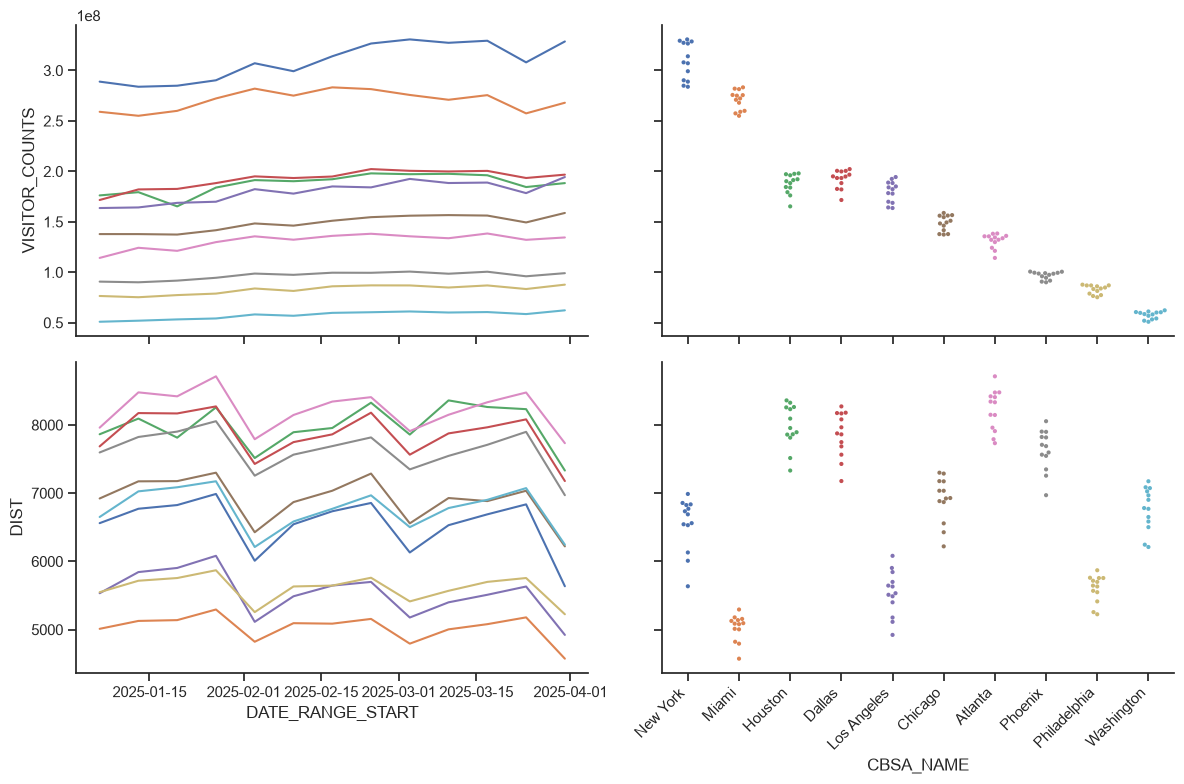

In [6]:
fig, axes = plt.subplots(
    2, 2, 
    figsize=(12,8),
    sharex="col",
    sharey="row",
)
axes = axes.flatten()
sns.lineplot(
    visits_per_day.to_pandas(),
    x="DATE_RANGE_START",
    y="VISITOR_COUNTS",
    hue="CBSA_NAME",
    legend=False,
    ax=axes[0]
)
sns.swarmplot(
    visits_per_day.to_pandas(),
    x="CBSA_NAME",
    y="VISITOR_COUNTS",
    hue="CBSA_NAME",
    s=3,
    ax=axes[1]
)
axes[1].tick_params("x", rotation=45, rotation_mode="xtick")

sns.lineplot(
    visits_per_day.to_pandas(),
    x="DATE_RANGE_START",
    y="DIST",
    hue="CBSA_NAME",
    legend=False,
    ax=axes[2]
)
sns.swarmplot(
    visits_per_day.to_pandas(),
    x="CBSA_NAME",
    y="DIST",
    hue="CBSA_NAME",
    s=3,
    ax=axes[3]
)
axes[3].tick_params("x", rotation=45, rotation_mode="xtick")

sns.despine()
fig.tight_layout()

## Extract segregation

We can use different definitions. For now, we use an adapted POI segregation from [Moro et al.](https://www.nature.com/articles/s41467-021-24899-8)

> To measure the income segregation of each place $\alpha$ in the city, we compute the proportion of total time spent at that place $\alpha$ by each income quartile $q$, $\tau _{q, \alpha}$, defining separate quartiles for each city. We define full integration of a place as $\tau _{q, \alpha} = \frac{1}{4}$ for each $q$, that is, the total time spent at venue $\alpha$ is split evenly across our four income quartiles. We then define the income segregation for each place $\alpha$, $S_\alpha$, as any deviation from our idealized measure of integration:
> $$S_{\alpha} = \frac{2}{3}\sum_{q=1}^{4}\left|\tau_{q\alpha} - \frac{1}{4}\right|$$

This definition generalizes to any number of groups as

$$
S_{\alpha}^{\{n\}} = \frac{n}{2n - 2}\sum_{q=1}^{n}\left|\tau_{q\alpha} - \frac{1}{n}\right|
$$

In [7]:
by = ["CBSAFP", "CBSA_NAME", "DATE_RANGE_START", "ID_STORE"]
visitor_distribution = (
    lf.filter(
        pl.col("HOME_INCOME_GROUP").is_not_null()
        & pl.col("VISITOR_COUNTS").is_not_null()
        & (pl.col("VISITOR_COUNTS") > 0)
    )
    .group_by([*by, "HOME_INCOME_GROUP"])
    .agg(pl.col("VISITOR_COUNTS").sum().alias("QUARTILE_VISITORS"))
    .with_columns(
        pl.col("QUARTILE_VISITORS").sum().over(by).alias("TOTAL_VISITORS")
    )
    .with_columns(
        (pl.col("QUARTILE_VISITORS") / pl.col("TOTAL_VISITORS")).alias("TAU")
    )
)

In [8]:
def l1_segregation(n: int) -> pl.Expr:
    expected_share = 1 / n
    normalization = n / (2 * (n - 1))
    return (normalization * (pl.col("TAU") - expected_share).abs().sum()).alias(
        "INCOME_SEGREGATION"
    )

segregation_expr = l1_segregation(n_income_groups)
poi_segregation = (
    visitor_distribution.group_by(by)
    .agg(
        pl.col("TOTAL_VISITORS").first(),
        segregation_expr,
    )
    .join(
        lf.group_by(by).agg(
            (
                (pl.col("DIST") * pl.col("VISITOR_COUNTS")).sum()
                / pl.col("VISITOR_COUNTS").sum()
            ).alias("DIST")
        ),
        on=by,
        how="left",
    )
)

In [9]:
segregation = poi_segregation.group_by("DATE_RANGE_START", "CBSAFP", "CBSA_NAME").agg(
    pl.col("TOTAL_VISITORS").sum(),
    pl.col("INCOME_SEGREGATION").mean().alias("AVG_INCOME_SEGREGATION"),
    ((pl.col("INCOME_SEGREGATION") * pl.col("TOTAL_VISITORS")).sum() / pl.col("TOTAL_VISITORS").sum()).alias("W_INCOME_SEGREGATION")
).collect().sort("DATE_RANGE_START", "TOTAL_VISITORS", descending=[False, True])
segregation.head()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

DATE_RANGE_START,CBSAFP,CBSA_NAME,TOTAL_VISITORS,AVG_INCOME_SEGREGATION,W_INCOME_SEGREGATION
datetime[μs],str,str,i32,f64,f64
2025-01-06 00:00:00,"""35620""","""New York""",288938230,0.38969,0.339731
2025-01-06 00:00:00,"""33100""","""Miami""",259046354,0.353281,0.267011
2025-01-06 00:00:00,"""26420""","""Houston""",176182780,0.363402,0.308985
2025-01-06 00:00:00,"""19100""","""Dallas""",171636751,0.369295,0.323595
2025-01-06 00:00:00,"""31080""","""Los Angeles""",163674841,0.379764,0.342739


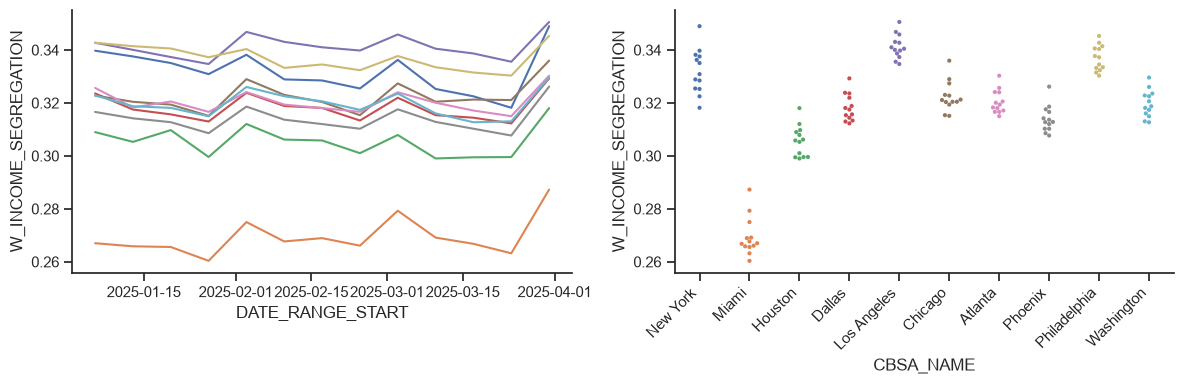

In [10]:
fig, axes = plt.subplots(
    1, 2, 
    figsize=(12,4)
)
sns.lineplot(
    segregation.to_pandas(),
    x="DATE_RANGE_START",
    y="W_INCOME_SEGREGATION",
    hue="CBSA_NAME",
    legend=False,
    ax=axes[0]
)
sns.swarmplot(
    segregation.to_pandas(),
    x="CBSA_NAME",
    y="W_INCOME_SEGREGATION",
    hue="CBSA_NAME",
    s=3,
    ax=axes[1]
)
axes[1].tick_params("x", rotation=45, rotation_mode="xtick")

sns.despine()
fig.tight_layout()

In [26]:
poi_seg

CBSAFP,CBSA_NAME,DATE_RANGE_START,ID_STORE,TOTAL_VISITORS,INCOME_SEGREGATION,DIST
str,str,datetime[μs],str,i32,f64,f64
"""35620""","""New York""",2025-03-31 00:00:00,"""10743165""",8755,0.250714,7022.555525
"""35620""","""New York""",2025-03-31 00:00:00,"""10323088""",2964,0.350202,2373.401944
"""35620""","""New York""",2025-03-31 00:00:00,"""6036334""",7010,0.597052,2905.596655
"""35620""","""New York""",2025-03-31 00:00:00,"""8359897""",638,0.276385,34782.902741
"""35620""","""New York""",2025-03-31 00:00:00,"""8276810""",714,0.429038,946.437655
…,…,…,…,…,…,…
"""16980""","""Chicago""",2025-03-17 00:00:00,"""312019""",431,0.397525,1311.651034
"""33100""","""Miami""",2025-03-17 00:00:00,"""9467169""",36,0.166667,4131.718606
"""47900""","""Washington""",2025-03-17 00:00:00,"""10442217""",311,0.5,6286.471412


## Model segregation at MSA level

In [11]:
df = segregation.with_columns(
    pl.col("DATE_RANGE_START").dt.date().alias("DATE")
).join(
    prism, 
    on=["CBSAFP", "DATE"],
).sort("DATE_RANGE_START", "TOTAL_VISITORS", descending=[False, True])
df

DATE_RANGE_START,CBSAFP,CBSA_NAME,TOTAL_VISITORS,AVG_INCOME_SEGREGATION,W_INCOME_SEGREGATION,DATE,AVG_TMEAN
datetime[μs],str,str,i32,f64,f64,date,f64
2025-01-06 00:00:00,"""35620""","""New York""",288938230,0.38969,0.339731,2025-01-06,-1.718441
2025-01-06 00:00:00,"""33100""","""Miami""",259046354,0.353281,0.267011,2025-01-06,17.197151
2025-01-06 00:00:00,"""26420""","""Houston""",176182780,0.363402,0.308985,2025-01-06,11.765132
2025-01-06 00:00:00,"""19100""","""Dallas""",171636751,0.369295,0.323595,2025-01-06,6.206542
2025-01-06 00:00:00,"""31080""","""Los Angeles""",163674841,0.379764,0.342739,2025-01-06,13.075422
…,…,…,…,…,…,…,…
2025-03-31 00:00:00,"""16980""","""Chicago""",158793856,0.377056,0.335974,2025-03-31,9.750559
2025-03-31 00:00:00,"""12060""","""Atlanta""",134507618,0.377249,0.330294,2025-03-31,19.410735
2025-03-31 00:00:00,"""38060""","""Phoenix""",99115678,0.372781,0.326162,2025-03-31,17.822105


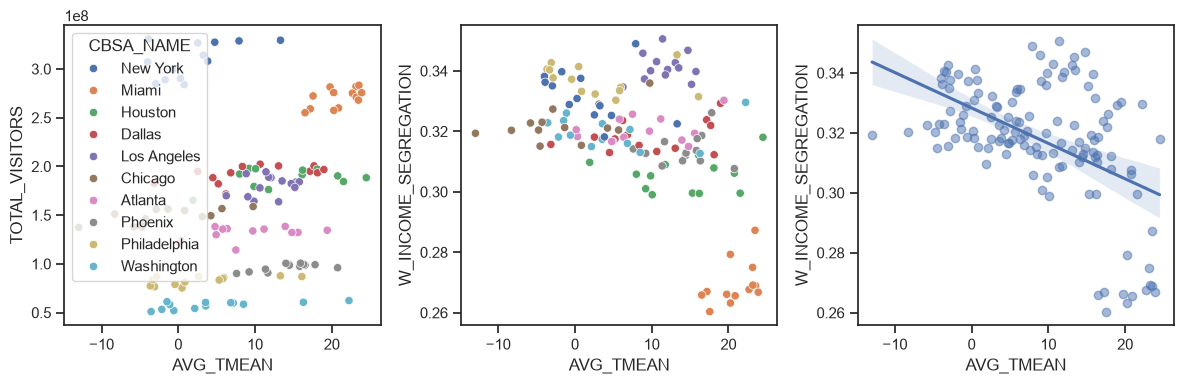

In [13]:
fig, axes = plt.subplots(
    1, 3,
    figsize=(12,4),
    sharex=True
)
sns.scatterplot(
    df.to_pandas(),
    x="AVG_TMEAN",
    y="TOTAL_VISITORS",
    hue="CBSA_NAME",
    ax=axes[0]
)

sns.scatterplot(
    df.to_pandas(),
    x="AVG_TMEAN",
    y="W_INCOME_SEGREGATION",
    hue="CBSA_NAME",
    ax=axes[1],
    legend=False
)

sns.regplot(
    data=df.to_pandas(),
    x="AVG_TMEAN",
    y="W_INCOME_SEGREGATION",
    scatter_kws={"alpha": 0.5},
    ax=axes[2]
)
fig.tight_layout()

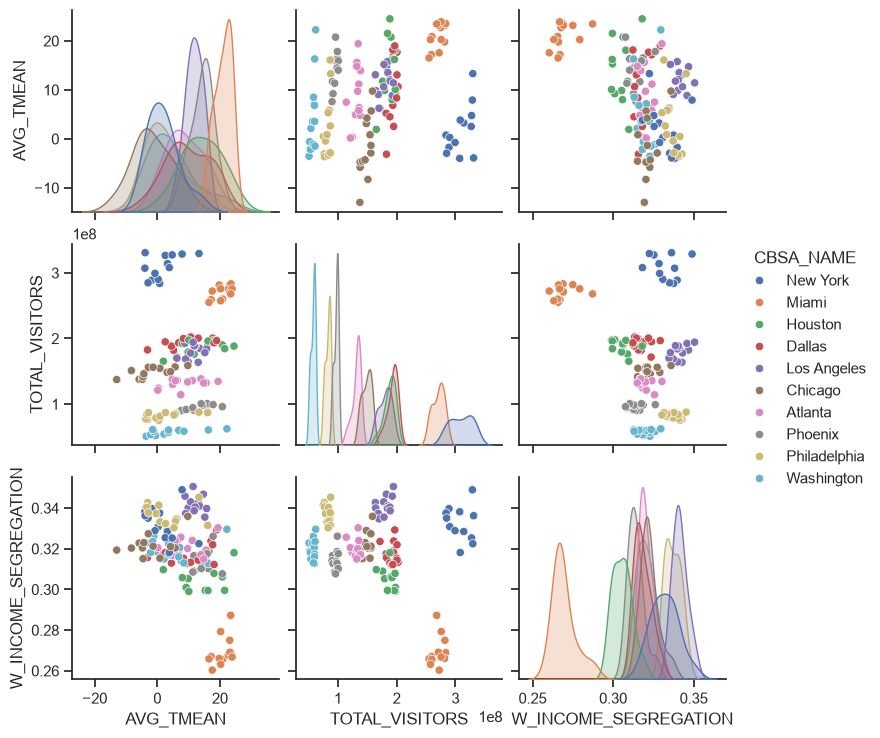

In [14]:
sns.pairplot(df.select(["CBSA_NAME", "AVG_TMEAN", "TOTAL_VISITORS", "W_INCOME_SEGREGATION"]).to_pandas(), hue="CBSA_NAME")

In [15]:
pdf = df.to_pandas()
m = smf.ols(
    "W_INCOME_SEGREGATION ~ AVG_TMEAN + C(CBSAFP) + C(DATE)",
    data=pdf
).fit(cov_type="cluster", cov_kwds={"groups": pdf["CBSAFP"]})

print(m.summary())

                             OLS Regression Results                             
Dep. Variable:     W_INCOME_SEGREGATION   R-squared:                       0.986
Model:                              OLS   Adj. R-squared:                  0.983
Method:                   Least Squares   F-statistic:                     969.4
Date:                  Tue, 13 Oct 2026   Prob (F-statistic):           2.39e-12
Time:                          14:52:34   Log-Likelihood:                 601.18
No. Observations:                   130   AIC:                            -1156.
Df Residuals:                       107   BIC:                            -1090.
Df Model:                            22                                         
Covariance Type:                cluster                                         
                                                  coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------

/Users/marfri/Desktop/weekly-patterns-plus-exploration/.venv/lib/python3.14/site-packages/statsmodels/base/model.py:1988: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 22, but rank is 9
  res = self.wald_test(


In [16]:
df

DATE_RANGE_START,CBSAFP,CBSA_NAME,TOTAL_VISITORS,AVG_INCOME_SEGREGATION,W_INCOME_SEGREGATION,DATE,AVG_TMEAN
datetime[μs],str,str,i32,f64,f64,date,f64
2025-01-06 00:00:00,"""35620""","""New York""",288938230,0.38969,0.339731,2025-01-06,-1.718441
2025-01-06 00:00:00,"""33100""","""Miami""",259046354,0.353281,0.267011,2025-01-06,17.197151
2025-01-06 00:00:00,"""26420""","""Houston""",176182780,0.363402,0.308985,2025-01-06,11.765132
2025-01-06 00:00:00,"""19100""","""Dallas""",171636751,0.369295,0.323595,2025-01-06,6.206542
2025-01-06 00:00:00,"""31080""","""Los Angeles""",163674841,0.379764,0.342739,2025-01-06,13.075422
…,…,…,…,…,…,…,…
2025-03-31 00:00:00,"""16980""","""Chicago""",158793856,0.377056,0.335974,2025-03-31,9.750559
2025-03-31 00:00:00,"""12060""","""Atlanta""",134507618,0.377249,0.330294,2025-03-31,19.410735
2025-03-31 00:00:00,"""38060""","""Phoenix""",99115678,0.372781,0.326162,2025-03-31,17.822105


In [18]:
poi_seg = poi_segregation.collect()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

CBSAFP,CBSA_NAME,DATE_RANGE_START,ID_STORE,TOTAL_VISITORS,INCOME_SEGREGATION,DIST
str,str,datetime[μs],str,i32,f64,f64
"""35620""","""New York""",2025-03-31 00:00:00,"""10743165""",8755,0.250714,7022.555525
"""35620""","""New York""",2025-03-31 00:00:00,"""10323088""",2964,0.350202,2373.401944
"""35620""","""New York""",2025-03-31 00:00:00,"""6036334""",7010,0.597052,2905.596655
"""35620""","""New York""",2025-03-31 00:00:00,"""8359897""",638,0.276385,34782.902741
"""35620""","""New York""",2025-03-31 00:00:00,"""8276810""",714,0.429038,946.437655
…,…,…,…,…,…,…
"""16980""","""Chicago""",2025-03-17 00:00:00,"""312019""",431,0.397525,1311.651034
"""33100""","""Miami""",2025-03-17 00:00:00,"""9467169""",36,0.166667,4131.718606
"""47900""","""Washington""",2025-03-17 00:00:00,"""10442217""",311,0.5,6286.471412


<Axes: xlabel='INCOME_SEGREGATION', ylabel='Density'>

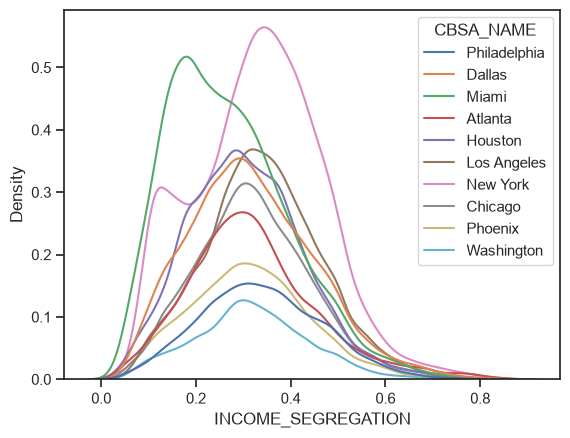

In [24]:
sns.kdeplot(
    poi_seg.group_by("ID_STORE", "CBSA_NAME").agg(
        pl.col("INCOME_SEGREGATION").mean(),
        pl.col("TOTAL_VISITORS").sum()
    ).to_pandas(),
    x="INCOME_SEGREGATION",
    hue="CBSA_NAME",
    weights="TOTAL_VISITORS"
)

In [ ]:
pdf = df.to_pandas()

pdf["AVG_TMEAN_CENTERED"] = (
    pdf["AVG_TMEAN"] - pdf["AVG_TMEAN"].mean()
)

m = smf.ols(
    """
    INCOME_SEGREGATION
    ~ AVG_TMEAN_CENTERED * C(POI_TYPE)
    + C(ID_STORE)
    + C(DATE)
    """,
    data=pdf,
).fit(
    cov_type="cluster",
    cov_kwds={"groups": pdf["CBSAFP"]},
)

print(m.summary())